In [ ]:

import os
import torch
os.environ["CUDA_VISIBLE_DEVICES"] = "3" #due to the impossibility of changing args.device in SFTTrainer :(

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent.parent))

from transformers import AutoModelForCausalLM

from peft import LoraConfig, get_peft_model, TaskType
from gptqmodel import GPTQModel
from gptqmodel.utils.backend import BACKEND

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lora_transfer_pruning").is_dir())
sys.path.insert(0, str(ROOT))


In [ ]:
from datetime import datetime
def save_profiler_to_json_with_timestamp(profiler: torch.profiler.profile, comment='str'):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    profiler.export_chrome_trace(f"profile_{timestamp}_{comment}.json")

In [ ]:
DEVICE = "cuda:0"  # physical cuda:3 after remapping
MODEL = "Qwen/Qwen3-30B-A3B-GPTQ-Int4"

In [ ]:
print(os.environ.get("HF_HUB_CACHE"))
os.environ["HF_HUB_OFFLINE"] = "1"


/glazkov-dev/.cache


## LORA CONFIG

In [ ]:
FRACTION_ATTN_LAYERS = [45, 46, 47]
FRACTION_MLP_LAYERS = [45, 46, 47] 

In [ ]:
config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=16, 
    lora_alpha=32, 
    lora_dropout=0.0, 
    bias="none",
    target_parameters = [], #important!
    #finds nn.Parameters, but after GPTQ they are modules!
    # target_parameters=[ f"model.layers.{layer}.mlp.experts.down_proj"
    #     for layer in FRACTION_MLP_LAYERS #layers_to_transform doesnt affect on parameters
    # ], #+ ["gate_up_proj"], #"gate_up_proj"
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj", "up_proj", "down_proj", "gate_proj"],
    layers_to_transform = FRACTION_ATTN_LAYERS
)

In [ ]:
print(config.target_modules)
print(config.target_parameters)

{'o_proj', 'gate_proj', 'q_proj', 'down_proj', 'k_proj', 'up_proj', 'v_proj'}
[]


## LOAD DATASET

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL)

#its instruct model, but we can measure general capabilities of model and perplexity on wikitext before
#and after pruning and fine-tuning
dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="validation",
)
dataset

INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/tokenizer_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO:httpx:H

Dataset({
    features: ['text'],
    num_rows: 3760
})

In [ ]:
CONTEXT_LENGTH = 128


In [ ]:
from transformers import DataCollatorForLanguageModeling

train_dataset, eval_dataset, data_collator = None, None, None

def tokenize_dataset():
    '''Ordinary truncative tokenizer'''
    global train_dataset, eval_dataset, data_collator
    
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    def tokenize_function(dataset_item_batch):
        #Исходные длины:    50, 300, 1000 токенов
        # После обработки:  50, 128,  128 токенов
        # Отброшено:         0, 172,  872 токена
        
        print("ds item", dataset_item_batch['text'].__len__(), dataset_item_batch)
        non_empty_texts = [text for text in dataset_item_batch["text"] if text.strip()]
        tokenized = tokenizer(
            non_empty_texts,
            truncation=True,
            padding=False,
            max_length=CONTEXT_LENGTH,
            return_overflowing_tokens=True,
            stride=0,
        )
        # print(tokenized['input_ids'].__len__())
        return tokenized

    original_columns = dataset.column_names
    tokenized_dataset = dataset.map(
        tokenize_function,
        batched=True,
        batch_size=1024, #for calling tokenize_function for huge batches of text, not batches for model.forward()!
        remove_columns=original_columns,
        desc=f"Tokenizing (max_length={CONTEXT_LENGTH})",
        # num_proc=8
    )

    tokenized_dataset = tokenized_dataset.remove_columns(["overflow_to_sample_mapping"])
    train_test_split = tokenized_dataset.train_test_split(test_size=0.2, seed=42)
    train_dataset = train_test_split["train"]
    eval_dataset = train_test_split["test"]
    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer,
        mlm=False, #not BERT, causal LM (Llama) (Masked Language Model)
        return_tensors="pt",
    )

tokenize_dataset()
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(eval_dataset)}")
print("example from dataset", next(iter(dataset)))
print("len", len(next(iter(dataset))))
# print("MODEL DEVICE", model.device)
print("example of input_ids", next(iter(train_dataset))["input_ids"])

print("example of input_ids", train_dataset[1]["input_ids"])
print(len(next(iter(train_dataset))["input_ids"]))
print("Tokenized columns:", train_dataset.column_names)

Training samples: 2888
Validation samples: 722
example from dataset {'text': ''}
len 1
example of input_ids [715]
example of input_ids [284, 284, 39632, 5729, 3840, 284, 284, 715]
1
Tokenized columns: ['input_ids', 'attention_mask']


In [ ]:
train_dataset[1]

{'input_ids': [284, 284, 39632, 5729, 3840, 284, 284, 715],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}

## TRAINERS

In [ ]:
from peft import PeftModel
from transformers import PreTrainedModel
from trl import SFTTrainer, SFTConfig


NUM_EVAL_BLOCKS = 8 #(block=batch)
EVAL_BATCH_SIZE = 8

NUM_STEPS = 500
PRINT_EVERY = 1
BATCH_SIZE = 8


per_device_train_batch_size = BATCH_SIZE
gradient_accumulation_steps = 1 #2 TODO if needed 09.11.2026
num_train_epochs = 5
learning_rate = 3e-4
logging_steps = PRINT_EVERY
SEED = 0

def create_trainer_unsloth(model: str | PreTrainedModel | PeftModel, optimizer):
    args=SFTConfig(
                #max_seq_length=MAX_CONTEXT_LENGTH,
                per_device_train_batch_size=per_device_train_batch_size,
                gradient_accumulation_steps=gradient_accumulation_steps,
                warmup_steps=2,
                num_train_epochs=num_train_epochs,
                #max_steps=30,  # TODO: experiment with different values (try 60–200)
                learning_rate=learning_rate,  # TODO: experiment with different values (try 1e-4 to 5e-4)
                logging_steps=logging_steps,
                
                # do_eval=False,
                # eval_strategy="no",
                do_eval=True,
                eval_strategy="steps",
                eval_steps=logging_steps,
                per_device_eval_batch_size=EVAL_BATCH_SIZE,
                eval_accumulation_steps=None, #не аккумулируем для экономии на метрике
                prediction_loss_only=True, #predicts only loss for eval
                
                gradient_checkpointing=False,
                bf16=True,
                logging_strategy="steps",
                logging_first_step=True,
                save_strategy="no", #sftconfig cant save model_bridge because of ._original_component aliases inside model
                #output_dir="outputs",
                #optim=optimizer,
                #weight_decay=0.01,
                #lr_scheduler_type="linear",
                #seed=SEED,
                # report_to="mlflow",
            )
    # args.device = DEVICE
    
    trainer = SFTTrainer( #supervised fine-tunning trainer
        model=model,
        train_dataset=train_dataset.select(range(32)),# TODO fix 09.11.2026
        eval_dataset=eval_dataset.select(
            range(min(NUM_EVAL_BLOCKS, len(eval_dataset)))
        ),
        processing_class=tokenizer,
        optimizers=optimizer,
        data_collator=data_collator,
        #compute_loss_func = None, #for the correct work of grad_accumulation logic when loss / grad_acum in Trainer
        #dont help compute_loss_func = None
        args = args
        # callbacks=[experiment_utils.UpdateGapMLflowCallback(), 
                # experiment_utils.SystemMetricsCallback()]
    )
    # trainer.add_callback(experiment_utils.PerplexityCallback(trainer.get_eval_dataloader(), max_batches=5, eval_every_n_steps=5))
    # trainer.add_callback(experiment_utils.PreciseMemoryCallback())
    #  trainer.add_callback(experiment_utils.ActivationMemoryCallback())
    #почему то unsloth не хочет ставить оптимизатор из optimizers и ставит стандартный из SFTConfig.optim - adam
    trainer.optimizer = optimizer[0]
    trainer.lr_scheduler = optimizer[1]
    return trainer

In [ ]:
optimizer_factory = lambda params: (torch.optim.SGD( #works better than AdamW consuming lots of memory
    params,
    lr=learning_rate, #1e-3 too much
    momentum=0.9,
    weight_decay=0.0,
    dampening=0.0,
    nesterov=True
), None) #second None - lr scheduler

In [ ]:
from unittest.mock import patch

quantized_model = GPTQModel.load(
    MODEL, 
    device=DEVICE, 
    backend=BACKEND.GPTQ_TORCH, 
    profile="low_memory",
)
with patch( # PEFT dont know that expert's Parameters became independent Modules.
    "peft.utils.transformers_weight_conversion.convert_peft_config_for_transformers",
    return_value=None,
):
    model = get_peft_model(quantized_model, config) 

def load_model():
    #вынесли для удобства
    return model.base_model.model.model

# PeftModel
# └── base_model: LoraModel          
#     └── model: Qwen3MoeQModel      ← GPTQ-обёртка
#         └── model: Qwen3MoeForCausalLM
#             └── model: Qwen3MoeModel
#                 └── embed_tokens

INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"


from_quantized: adapter: None


INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/revision/main "HTTP/1.1 200 OK"


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

... (18 outputs left out)

INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "use_cache": true
}



INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.


INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}



INFO  Kernel: loaded -> `[TorchLinear]`                                        


In [ ]:
# FROZE_N_LAYERS = -1 
ATTN_OUT_FRACTION = 0.3
MLP_OUT_FRACTION = 0.3
FRACTION_SEED=0

In [ ]:
from experiments.compare_tp_and_our.prune_and_train_model_for_comparsion import full_load_prune_learn_pipeline

# torch.cuda.memory._record_memory_history()

# trainer = full_load_prune_learn_pipeline(MODEL,
#                                load_model,
#                                torch.tensor(next(iter(train_dataset))['input_ids'])[None, ...], #evaluation_blocks[:BATCH_SIZE], #will learn 1 batch every time
                               
#     FRACTION_ATTN_LAYERS, FRACTION_MLP_LAYERS, ATTN_OUT_FRACTION, MLP_OUT_FRACTION,
#     is_torch_pruning=False,
#     rescale=False,
#     seed=FRACTION_SEED,
#     batch_size=BATCH_SIZE,
#     optimizer_factory=optimizer_factory,
#     num_steps=NUM_STEPS,
#     print_every=PRINT_EVERY,
#     #froze_n_layers=FROZE_N_LAYERS, dont need to mention in gptq format
#     trainer_factory=create_trainer_unsloth,
#     froze_embed=True,
#     froze_unembed=False
# )

# timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
# torch.cuda.memory._dump_snapshot(f"deepseek_prune_our_bs{BATCH_SIZE}x{CONTEXT_LENGTH}_train_ds_{timestamp}.pickle")

## GROUP debug

In [ ]:

if (False):
    import torch_pruning as tp

    from transformer_lens.model_bridge.transformer_bridge import TransformerBridge
    from gptqmodel.nn_modules.qlinear.torch import TorchLinear
    from lora_transfer_pruning.adapter.torch_pruning.custom_pruners import GPTQDepGraphOnlyPruner
    from lora_transfer_pruning.adapter.torch_pruning.torch_pruning_group_builder import TorchPruningGroupBuilder

    loaded_model = load_model()
    #NOTE: think to extract in core module this things...

    bridge = TransformerBridge.boot_transformers(
        MODEL,
        hf_model=loaded_model,
        # dtype=torch.float16,
    )


    DG = tp.DependencyGraph().build_dependency(
        bridge,
        example_inputs=torch.tensor(next(iter(train_dataset))['input_ids'])[None, ...].to(DEVICE),
        forward_fn=TorchPruningGroupBuilder._trace_forward,
        ignored_params=[],
        customized_pruners={ #NOTE: вынести тоже в core или куда-то (usecase)
            TorchLinear: GPTQDepGraphOnlyPruner(),
        },
        #unwrapped_parameters=list(zip(ignored_params, [_] * len(ignored_params)))
    )

    group = DG.get_pruning_group(
    bridge.blocks[47].attn.q.lora_B['default'],
    tp.prune_linear_out_channels, 
    idxs=[2, 6, 9] )

    print(group)

## TRAIN

NOTE: we need custom adapter, to help TransformerLens to convert model to bridged version for MOE module. (after gptq there are independent up_proj, down_proj, etc. in Qwen3MoeMLP)

In [ ]:
from transformer_lens.factories.architecture_adapter_factory import ArchitectureAdapterFactory
from transformer_lens.model_bridge.transformer_bridge import TransformerBridge
from experiments.utils.compare_utils import create_prune_task
from lora_transfer_pruning.core.prune_task_type import GroupPruneTask, ModelPruneTask
from experiments.compare_tp_and_our.prune_and_train_model_for_comparsion import get_learn_stat_for_some_pruning
from lora_transfer_pruning.core.tl_adapters import Qwen3MoeWithExpertBridges

loaded_model = load_model()

#NOTE: think to extract in core module this things...
ArchitectureAdapterFactory.register_adapter(
    "Qwen3MoeForCausalLM",
    Qwen3MoeWithExpertBridges,
)
bridge = TransformerBridge.boot_transformers(
    MODEL,
    hf_model=loaded_model,
    # dtype=torch.float16,
)
    
    # prune_task = create_prune_task(FRACTION_ATTN_LAYERS,
    #                                FRACTION_MLP_LAYERS,
    #                                ATTN_OUT_FRACTION,
    #                                MLP_OUT_FRACTION,
    #                                "default",
    #                                "q_proj",
    #                                "up_proj")

INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Qwen/Qwen3-30B-A3B-GPTQ-Int4/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/9b534e4318b7ebc3c961a839f13eb18b1833f441/tokenizer_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen3-30B-A3B-GPTQ-Int4/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO:httpx:H

In [ ]:
bridge.device
bridge.dtype
from transformers import Qwen3MoeConfig
bridge.config.hidden_size

2048

In [ ]:
bridge.blocks[0].mlp.experts[0].hook_in.name

'blocks.0.mlp.experts.0.hook_in'

In [ ]:
bridge.blocks[0].mlp.experts[0].name

'experts.0'

#10.11.2026 - too long computations for all 48 layers and last 3 with lora. (because of dequant and so on)
#lets try to learn only last layers!

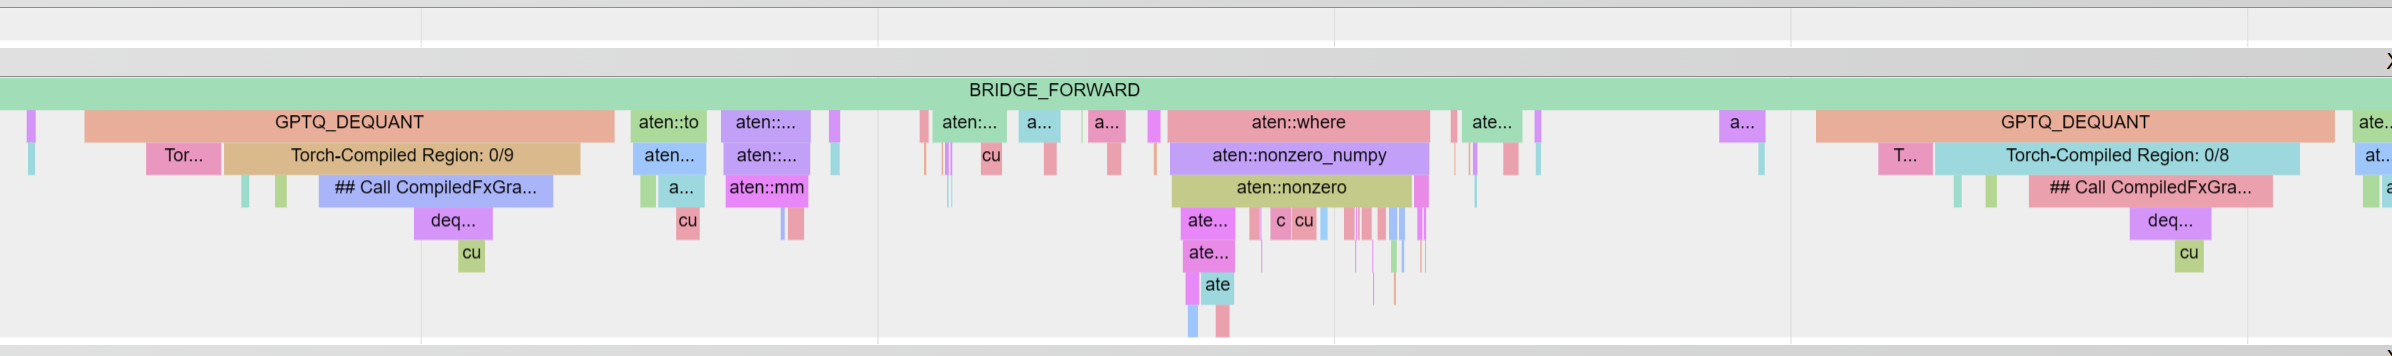

In [ ]:
# Before pruning: {'eval_loss': 3.3123040199279785, 'eval_model_preparation_time': 5.9984, 'eval_runtime': 14.7026, 'eval_samples_per_second': 0.544, 'eval_steps_per_second': 0.068}
# {'eval_loss': '3.304', 'eval_model_preparation_time': '5.998', 'eval_runtime': '7.164', 'eval_samples_per_second': '1.117', 'eval_steps_per_second': '0.14', 'eval_entropy': '2.512', 'eval_num_tokens': '0', 'eval_mean_token_accuracy': '0.394', 'epoch': 0}
# After pruning: {'eval_loss': 3.3041605949401855, 'eval_model_preparation_time': 5.9984, 'eval_runtime': 7.1639, 'eval_samples_per_second': 1.117, 'eval_steps_per_second': 0.14}
# Профиль сохранён

In [ ]:
# первые 45 слоёв заморожены (кажется не даёт импакта)
# Before pruning: {'eval_loss': 3.3123040199279785, 'eval_model_preparation_time': 8.6304, 'eval_runtime': 15.9587, 'eval_samples_per_second': 0.501, 'eval_steps_per_second': 0.063}
# {'eval_loss': '3.304', 'eval_model_preparation_time': '8.63', 'eval_runtime': '6.064', 'eval_samples_per_second': '1.319', 'eval_steps_per_second': '0.165', 'eval_entropy': '2.512', 'eval_num_tokens': '0', 'eval_mean_token_accuracy': '0.394', 'epoch': 0}
# After pruning: {'eval_loss': 3.3041605949401855, 'eval_model_preparation_time': 8.6304, 'eval_runtime': 6.064, 'eval_samples_per_second': 1.319, 'eval_steps_per_second': 0.165}
# Профиль сохранён

In [ ]:
from torch.profiler import profile, ProfilerActivity, record_function


prune_task_name = "default"
q_proj_name = "q"
mlp_up_proj_name = "up_proj"
attn_out_fraction = ATTN_OUT_FRACTION
mlp_out_fraction = MLP_OUT_FRACTION
fraction_attn_layers = FRACTION_ATTN_LAYERS
fraction_mlp_layers = FRACTION_MLP_LAYERS
EXPERTS_COUNT = bridge.blocks[0].mlp.experts.__len__()
evaluation_batches = torch.tensor(next(iter(train_dataset))['input_ids'])[None, ...]

fraction_prune_task = {
            **{
                f"blocks.{layer}.attn.{q_proj_name}": GroupPruneTask(None, attn_out_fraction)
                for layer in fraction_attn_layers
            },
            # **{
            #     f"blocks.{layer}.mlp.{mlp_up_proj_name}": GroupPruneTask(None, mlp_out_fraction)
            #     for layer in fraction_mlp_layers
            # },
            
            #NOTE: для экспертов надо пройтись по всем экспертам отдельно
            **{
                f"blocks.{layer}.mlp.experts.{expert}.{mlp_up_proj_name}": GroupPruneTask(None, mlp_out_fraction)
                for expert in range(EXPERTS_COUNT) for layer in fraction_mlp_layers
            },
        }
model_prune_task = ModelPruneTask(fraction_prune_task, prune_task_name)
    #todo today 06 11 2026

try:
   
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA], 
                #  with_stack=True, 
                record_shapes=True,
                #experimental_config=torch._C._profiler._ExperimentalConfig(verbose=True),
                ) as profiler:
        with record_function("BEFORE get_learn_stat_for_some_pruning"):
            learning_history = get_learn_stat_for_some_pruning(bridge, 
                                                                model_prune_task, 
                                                                SEED, 
                                                                evaluation_batches, 
                                                                rescale=False, 
                                                                is_torch_pruning=False,
                                                                batch_size=BATCH_SIZE,
                                                                optimizer_factory=optimizer_factory,
                                                                num_steps=NUM_STEPS,
                                                                print_every=PRINT_EVERY,
                                                                n_layers_froze=45,
                                                                trainer_factory=create_trainer_unsloth,
                                                                froze_embed=True,
                                                                froze_unembed=False)
except KeyboardInterrupt:
    print("Прервано пользователем")
finally:
    save_profiler_to_json_with_timestamp(profiler, comment="qwen_3_30b_long_eval")
    print("Профиль сохранён")


/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch/profiler/profiler.py:217: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Getting fraction prune_task...:
  blocks.45.attn.q: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.46.attn.q: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.47.attn.q: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.45.mlp.experts.0.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.46.mlp.experts.0.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.47.mlp.experts.0.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.45.mlp.experts.1.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.46.mlp.experts.1.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.47.mlp.experts.1.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.45.mlp.experts.2.up_proj: GroupPruneTask(cols=None, rows=0.3, kv_lora_idxs_deepseek=None)
  blocks.46.mlp.experts

/glazkov-dev/LoRa-Transfer-Pruning/.venv/lib/python3.10/site-packages/torch_pruning/dependency/graph.py:390: UserWarning: Unwrapped parameters detected: ['model.layers.4._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.6._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.9._original_component.mlp._original_component.gate._original_component.weight', 'model.layers.18._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.26._original_component.post_attention_layernorm._original_component.weight', 'model.layers.33._original_component.self_attn._original_component.q_norm._original_component.weight', 'model.layers.38._original_component.self_attn._original_component.k_norm._original_component.weight', 'model.layers.41._original_component.mlp._original_component.gate._original_component.weight', 'model.layers.38._original_component.post_attention_l

Tracing expert blocks.0.mlp.experts.0 with synthetic input
Tracing expert blocks.0.mlp.experts.1 with synthetic input
Tracing expert blocks.0.mlp.experts.2 with synthetic input
Tracing expert blocks.0.mlp.experts.3 with synthetic input
Tracing expert blocks.0.mlp.experts.4 with synthetic input
Tracing expert blocks.0.mlp.experts.5 with synthetic input
Tracing expert blocks.0.mlp.experts.6 with synthetic input
Tracing expert blocks.0.mlp.experts.7 with synthetic input
Tracing expert blocks.0.mlp.experts.8 with synthetic input
Tracing expert blocks.0.mlp.experts.9 with synthetic input
Tracing expert blocks.0.mlp.experts.10 with synthetic input
Tracing expert blocks.0.mlp.experts.11 with synthetic input
Tracing expert blocks.0.mlp.experts.12 with synthetic input
Tracing expert blocks.0.mlp.experts.13 with synthetic input
Tracing expert blocks.0.mlp.experts.14 with synthetic input
Tracing expert blocks.0.mlp.experts.15 with synthetic input
Tracing expert blocks.0.mlp.experts.16 with synthe

In [1]:
# {'eval_loss': '3.312', 'eval_model_preparation_time': '8.652', 'eval_runtime': '16.6', 'eval_samples_per_second': '0.482', 'eval_steps_per_second': '0.06', 'eval_entropy': '2.52', 'eval_num_tokens': '0', 'eval_mean_token_accuracy': '0.3919', 'epoch': 0}
# Before pruning: {'eval_loss': 3.3123040199279785, 'eval_model_preparation_time': 8.6523, 'eval_runtime': 16.5981, 'eval_samples_per_second': 0.482, 'eval_steps_per_second': 0.06}
# {'eval_loss': '3.304', 'eval_model_preparation_time': '8.652', 'eval_runtime': '6.284', 'eval_samples_per_second': '1.273', 'eval_steps_per_second': '0.159', 'eval_entropy': '2.512', 'eval_num_tokens': '0', 'eval_mean_token_accuracy': '0.394', 'epoch': 0}
# After pruning: {'eval_loss': 3.3041605949401855, 'eval_model_preparation_time': 8.6523, 'eval_runtime': 6.2843, 'eval_samples_per_second': 1.273, 'eval_steps_per_second': 0.159}
# {'loss': '2.784', 'grad_norm': '0.7782', 'learning_rate': '0', 'entropy': '1.764', 'num_tokens': '911', 'mean_token_accuracy': '0.4673', 'epoch': '0.25'}
# {'eval_loss': '3.3', 'eval_model_preparation_time': '8.652', 'eval_runtime': '4.772', 'eval_samples_per_second': '1.676', 'eval_steps_per_second': '0.21', 'eval_entropy': '2.514', 'eval_num_tokens': '5014', 'eval_mean_token_accuracy': '0.3919', 'epoch': '2'}
# {'train_runtime': '145.7', 'train_samples_per_second': '0.439', 'train_steps_per_second': '0.055', 'train_loss': '2.848', 'epoch': '2'}
# Профиль сохранён

## DEBUG SECTION

In [ ]:
bridge.blocks[47].mlp.experts

ModuleList(
  (0-127): 128 x Qwen3MoeMLP(
    (gate_proj): lora.GPTQLoraLinear(
      (base_layer): TorchLinear()
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): ModuleDict(
        (default): Linear(in_features=2048, out_features=16, bias=False)
      )
      (lora_B): ModuleDict(
        (default): Linear(in_features=16, out_features=768, bias=False)
      )
      (lora_embedding_A): ParameterDict()
      (lora_embedding_B): ParameterDict()
      (lora_magnitude_vector): ModuleDict()
      (quant_linear_module): TorchLinear()
    )
    (up_proj): lora.GPTQLoraLinear(
      (base_layer): TorchLinear()
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): ModuleDict(
        (default): Linear(in_features=2048, out_features=16, bias=False)
      )
      (lora_B): ModuleDict(
        (default): Linear(in_features=16, out_features=768, bias=False)
      )
      (lora_embedding_A): ParameterDict()
      (lora_embeddi

In [ ]:
model.base_model.model.model.model.layers[0].mlp

MoEBridge(
  (hook_in): HookPoint(name='blocks.0.mlp.hook_in')
  (hook_out): HookPoint(name='blocks.0.mlp.hook_out')
  (hook_router_scores): HookPoint(name='blocks.0.mlp.hook_router_scores')
  (_original_component): LinearQwen3MoeSparseMoeBlock(
    (gate): LinearBridge(name=gate, original_component=Qwen3MoeTopKRouter)
    (experts): ModuleList(
      (0-127): 128 x Qwen3MoeMLP(
        (gate_proj): TorchLinear()
        (up_proj): TorchLinear()
        (down_proj): TorchLinear()
        (act_fn): SiLUActivation()
      )
    )
  )
  (gate): LinearBridge(name=gate, original_component=Qwen3MoeTopKRouter)
)

# Metrics SECTION

In [25]:
learning_history

In [26]:
def plot_training_history(history, *, title="Training dynamics"):
    """Plot interleaved Trainer train/eval logs in one figure."""
    import math
    import numbers
    import matplotlib.pyplot as plt

    if not history:
        raise ValueError("history is empty")

    aliases = {"gradient_norm": "grad_norm"}
    excluded = {
        "step", "epoch", "train_loss", "train_runtime",
        "train_samples_per_second", "train_steps_per_second",
        "eval_runtime", "eval_samples_per_second",
        "eval_steps_per_second", "total_flos",
    }

    series = {}
    for row in history:
        if not isinstance(row.get("step"), numbers.Number):
            continue
        step = row["step"]
        for raw_key, value in row.items():
            if raw_key in excluded or not isinstance(value, numbers.Number):
                continue
            split = "eval" if raw_key.startswith("eval_") else "train"
            metric = raw_key.removeprefix("eval_")
            metric = aliases.get(metric, metric)
            series.setdefault(metric, {}).setdefault(split, []).append(
                (step, float(value))
            )

    # Trainer normally logs loss but not perplexity. Derive it separately
    # for train and eval, so exp(mean loss) is shown at the same steps.
    if "loss" in series and "perplexity" not in series:
        series["perplexity"] = {
            split: [
                (step, math.exp(value) if value < 80 else math.inf)
                for step, value in points
            ]
            for split, points in series["loss"].items()
        }

    preferred_order = [
        "loss", "perplexity", "grad_norm", "learning_rate",
        "mean_token_accuracy", "entropy", "num_tokens",
    ]
    metric_names = [name for name in preferred_order if name in series]
    metric_names += [name for name in series if name not in metric_names]
    if not metric_names:
        raise ValueError("history contains no step-wise numeric metrics")

    labels = {
        "loss": "Loss",
        "perplexity": "Perplexity",
        "grad_norm": "Gradient norm",
        "learning_rate": "Learning rate",
        "mean_token_accuracy": "Mean token accuracy",
        "entropy": "Entropy",
        "num_tokens": "Processed tokens",
    }
    ncols = min(2, len(metric_names))
    nrows = math.ceil(len(metric_names) / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(7 * ncols, 4 * nrows),
        squeeze=False,
        sharex=True,
    )
    flat_axes = list(axes.flat)

    styles = {
        "train": dict(marker="o", linewidth=1.8, alpha=0.8),
        "eval": dict(marker="s", linewidth=2.4, linestyle="--"),
    }
    for ax, metric_name in zip(flat_axes, metric_names):
        label = labels.get(
            metric_name,
            metric_name.replace("_", " ").title(),
        )
        for split in ("train", "eval"):
            points = series[metric_name].get(split, [])
            if not points:
                continue
            steps, values = zip(*points)
            ax.plot(
                steps,
                values,
                label=split.capitalize(),
                **styles[split],
            )

        ax.set(
            title=label,
            xlabel="Optimizer step",
            ylabel=label,
        )
        ax.grid(True, alpha=0.3)
        ax.legend()

        if metric_name == "learning_rate":
            ax.ticklabel_format(
                axis="y",
                style="sci",
                scilimits=(0, 0),
            )

    for ax in flat_axes[len(metric_names):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig, axes


In [29]:
learning_history.state.log_history[0]

{'loss': 2.7839736938476562,
 'grad_norm': 0.7782047390937805,
 'learning_rate': 0.0,
 'entropy': 1.764297366142273,
 'num_tokens': 911.0,
 'mean_token_accuracy': 0.4673311114311218,
 'epoch': 0.25,
 'step': 1}

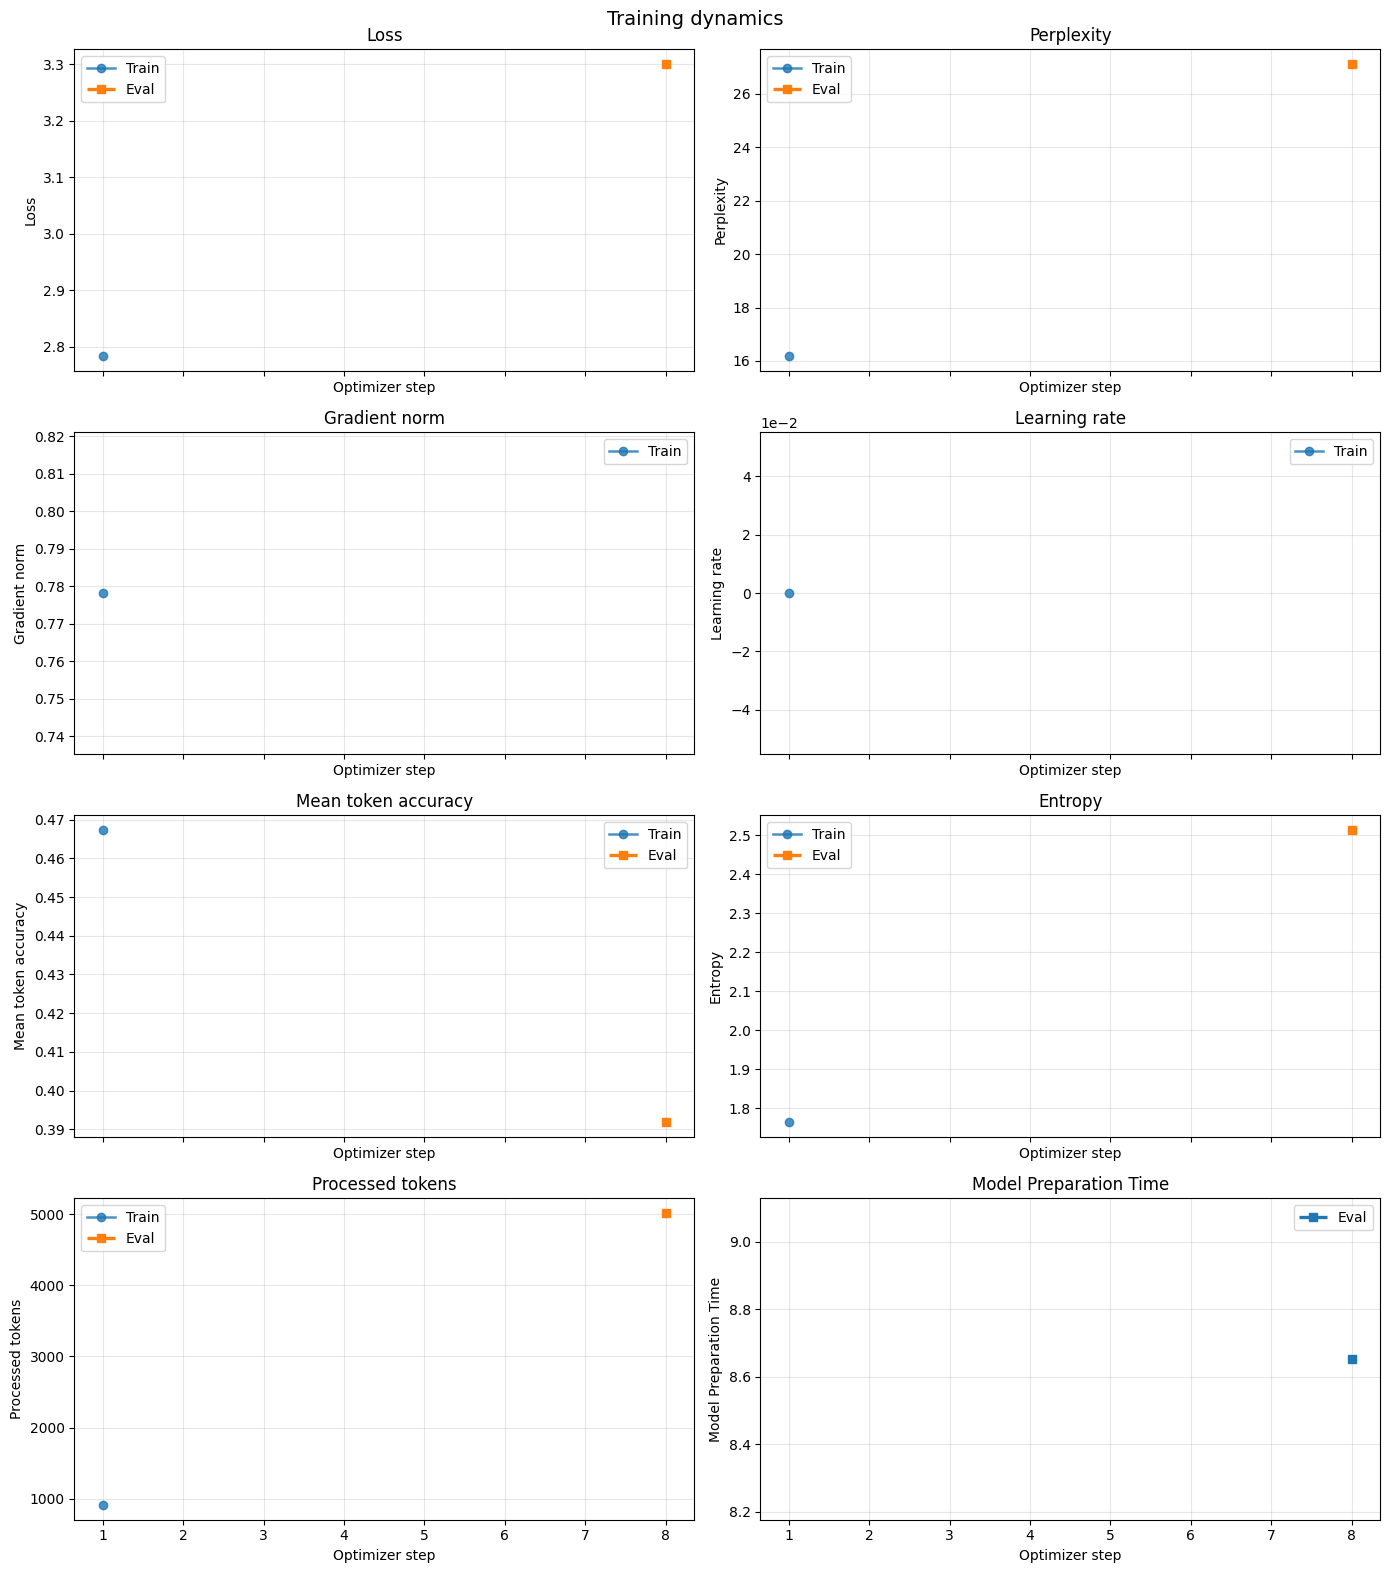

In [30]:
_ = plot_training_history(learning_history.state.log_history)